# Computer-generated hologram (CGH) — a diffractive optical element projects an image
A flat, wavelength-thin **phase plate** (a diffractive optical element, DOE) is
illuminated by a single plane wave and, purely by diffraction, reconstructs a
recognizable image — here the word mark "Wave / Sim" — in mid-air a short
distance downstream. There is no lens and no moving part: the entire image is
encoded in the height map of a transparent relief whose features are wavelength-
scale. The field at the reconstruction plane *is* the picture.

How the phase pattern is found (runs locally, in this script)
-------------------------------------------------------------
The DOE phase φ(y, z) is computed offline by the **Gerchberg–Saxton (GS)**
algorithm — a few dozen forward/back propagations between the DOE plane and the
image plane, each time keeping the phase but resetting the amplitude to the known
constraint (uniform illumination at the DOE, the target picture at the image). GS
is pure NumPy here (FFT-based **angular-spectrum** propagation); it is *not* the
wave solve. Its output is a continuous phase map that we then realize physically as
a surface-relief **kinoform**:

    φ(y, z) = k₀ · (n − 1) · h(y, z),   h wrapped into [0, λ/(n−1)) for a full 2π,

so the DOE is a transparent glass relief whose local height encodes the phase. The
script's job is to rasterize that relief into the per-voxel permittivity grid and
let the solver propagate the real field — the phase-retrieval is upstream.

Quality settings
----------------
Four levers set how crisp the image is:
  1. **Finer grid** — ``pixel_size = λ/6`` resolves the kinoform's wide-angle
     scatter instead of dumping it into the background.
  2. **Band-limited target** — the rendered glyphs are binarized then lightly
     Gaussian-blurred, so the target asks the DOE for low spatial frequencies it can
     actually deliver (sharp/aliased edges would scatter into speckle).
  3. **Speckle averaging** — ``n_seeds`` *independent* GS designs are each solved and
     their reconstructed intensities averaged. Phase-only CGH always carries speckle;
     averaging N statistically independent DOEs suppresses it by ~√N (the standard
     time-multiplexing despeckle). **Each seed is a full simulation; the default
     n_seeds = 1 solves a single design, without averaging.**
  4. **Aperture > image** — the DOE aperture is larger than the image, and the image
     fills only ``image_fraction`` of it. The extra space-bandwidth gives GS more
     degrees of freedom, and the dark guard border around the image is where GS dumps
     its reconstruction noise.

Why this needs a full-wave solver (and where scalar Fourier optics fails)
-------------------------------------------------------------------------
Scalar Fourier optics (the GS/angular-spectrum model) *designs* the DOE, but it
assumes a thin, infinitely-resolved phase screen and keeps only propagating plane-
wave orders. The real relief has finite thickness, voxel-quantized steps, wavelength-
scale features that scatter into high angles, and a substrate that reflects — all
near-field effects the thin-screen model omits. The full-wave solve reconstructs the
image *rigorously*, and the script reports how close the rigorous reconstruction is
to both the target and the thin-screen prediction. Image formation here is pure
coherent diffraction summed across the aperture — there is no ray-optics picture of
it, so a ray tracer cannot produce this image at all.

Physics / solver mode
---------------------
Scalar Helmholtz (one CW wavelength, linear, non-magnetic). Scalar is the standard
model for diffractive image formation (Fourier optics is scalar) and keeps the voxel
budget low. Output is the steady-state complex field; |field|² at the reconstruction
plane is the projected image.

Geometry (propagation = X; transverse image plane = Y, Z)
---------------------------------------------------------
Along +X: air gap → thin glass substrate → relief layer (the kinoform) → free-space
propagation → reconstruction plane → a little more air. The plane wave enters, the
relief imprints φ(y, z), and the image self-assembles by diffraction at x ≈
relief-exit + ``z_rec``. Open (absorbing) boundaries on all six faces; the plane
wave is Tukey-tapered to the aperture so it does not diffract off the domain edges.

Everything that sets the scene is a top-level variable so the example re-scales.

Outputs (saved in output/hmhz_hologram_cgh/)
-------------------------------------------------
  * cgh_reconstruction.png — target image | full-wave |E|² at the reconstruction
    plane (one design by default, averaged over n_seeds designs when n_seeds > 1) |
    thin-screen prediction, side by side;
  * cgh_propagation.png    — an X–Y cut (z = centre): plane wave → DOE relief
    → diffraction → image plane, plus the near-field just past the DOE;
  * cgh_volume.npy         — downsampled |field| volume (averaged over the seeds) for
    3-D rendering, plus cgh_index.npy (downsampled index map, seed 0) and
    cgh_phase.npy (the designed DOE phase map, seed 0).

The GS design, the target image, and the relief rasterization are all built locally
with NumPy/SciPy/Matplotlib.

Size: 392.1 Mvoxel including boundaries, 11.68 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from scipy.signal.windows import tukey
from scipy.ndimage import gaussian_filter

from wavesimpro import configure, simulate
from wsutils import output_dir

NAME = "hmhz_hologram_cgh"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME)

### Parameters

In [2]:
wavelength = 0.532  # Wavelength in micrometer (μm) — green light, in the air background
pixel_size = wavelength / 6  # (#1) Grid spacing in μm (~6 px/λ). The DOE is designed on
#                              this exact grid, so the kinoform is fully resolved and its
#                              wide-angle scatter is captured rather than lost. Use λ/4 for
#                              a coarser grid, λ/8 for a finer one.

n_doe = 1.5  # glass-like DOE / substrate index (real, low-loss); relief is the same material
n_bg = 1.0   # air (background and reconstruction medium)

# (#4) Aperture larger than the image → more DOE space-bandwidth; the image fills only
# image_fraction of it and the dark guard border is where GS dumps reconstruction noise.
aperture = 48.0        # side of the square DOE aperture (illumination + relief), μm. With
#                        image_fraction this sets the image size and the speckle grain
#                        (δ ≈ λ·z_rec/aperture): a larger aperture gives larger, cleaner
#                        letters that sit on a finer speckle background, at more voxels.
image_fraction = 0.80  # fraction of the aperture the target image spans; the rest is the dark
#                        guard border where the Gerchberg–Saxton design dumps its reconstruction
#                        noise. Smaller = cleaner but smaller image, larger = bigger image.
z_rec = 48.0           # reconstruction distance from the DOE exit plane, μm

target_text = "Wave\nSim"  # the wordmark the hologram reconstructs (a newline starts a new line).
#                            Works best as 2 short lines (≤ 3–4 letters each): fewer, larger
#                            glyphs reconstruct more cleanly than many small ones.
target_fontsize = 50  # glyph size on the render canvas — controls how much of the canvas the text
#                       fills (and its rendered detail). The image's physical size on the
#                       reconstruction plane is set by aperture × image_fraction, not by this.
target_rotate_k = 1  # rotate the target image by k*90° (np.rot90 convention). Set so the
#                      reconstruction reads upright in a 3-D view of the saved volume; the 2D
#                      Figure 1 panel then shows it rotated, which is expected. -1 = clockwise.

# (#2) Band-limit the target: binarize the rendered glyphs, then lightly blur so the DOE
# is asked only for spatial frequencies it can deliver (sharp edges → speckle).
target_binarize = True
target_blur_px = 1.5  # Gaussian blur sigma in pixels (0 disables)

# (#3) ===== SPECKLE AVERAGING ====================================================
# A phase-only CGH always reconstructs the image on top of a grainy speckle
# background. Averaging the intensities of N *independent* DOE designs (each started
# from a different random GS phase) suppresses that speckle by ~sqrt(N) — the standard
# time-multiplexing despeckle. It does NOT change the image structure (the glyphs are
# identical seed to seed); it only cleans up the background graininess.
#
#   *** EACH SEED IS A FULL SIMULATION. ***
#
# Default = 1: one simulation. The 2-D reconstruction plot is then one raw speckle
# realization — the wordmark is fully recognizable, just grainier.
#
# To push quality (smoother reconstruction), raise n_seeds:
#   n_seeds = 2 -> ~1.4x less speckle      n_seeds = 4 -> ~2x      n_seeds = 9 -> ~3x
n_seeds = 1
seed0 = 0  # base RNG seed; designs use seed0, seed0+1, … All seeds are statistically
#            equivalent independent draws — none is "better"; seed0 just picks which
#            speckle realization is the one simulated and saved.

gs_iterations = 60  # Gerchberg–Saxton iterations per design (run locally)

k0 = 2 * np.pi / wavelength
max_height = wavelength / (n_doe - 1)  # relief height spanning a full 2π, μm

# Domain layout along X (propagation): air gap → substrate → relief → free space → image.
x_src = 0.8       # plane-wave launch X, μm (in the air gap, after the absorbing boundary)
x_sub0 = 1.2      # substrate front face, μm
t_substrate = 1.0  # substrate thickness, μm
x_relief0 = x_sub0 + t_substrate     # relief base (on the substrate), μm
x_relief1 = x_relief0 + max_height   # tallest the relief can be (DOE exit plane), μm
x_image = x_relief1 + z_rec          # design reconstruction plane, μm
x_end = x_image + 4.0                # a little air beyond the image, μm

# Transverse window = aperture + guard (clears the diffracting field off the walls and
# leaves room for the image's noise-dump border).
transverse = aperture + 14.0  # μm (Y and Z)

sim_size = np.array([x_end, transverse, transverse])  # (x, y, z) μm
n_size = (sim_size / pixel_size).astype(int)
nx, ny, nz = (int(v) for v in n_size)
cy = cz = transverse / 2  # optical axis (Y, Z centre), μm

taper = 0.2          # Tukey taper fraction for the plane wave / illumination in Y, Z
vol_downsample = 2   # downsample factor for the saved 3-D volume

print(f"Domain {sim_size} μm = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.1f} Mvoxel without boundaries)")
print(f"DOE: aperture {aperture} μm, n={n_doe}, relief 0…{max_height:.3f} μm "
      f"(~{max_height / pixel_size:.0f} voxels, full 2π)")
print(f"Reconstruction at x ≈ {x_image:.1f} μm ({z_rec} μm past the DOE exit)")
if n_seeds == 1:
    print("Speckle averaging OFF (n_seeds=1): 1 simulation, one raw realization. "
          "Raise n_seeds for a smoother averaged plot (~sqrt(N) less speckle).")
else:
    print(f"Speckle averaging over {n_seeds} independent design(s) -> {n_seeds} "
          f"simulation(s), ~{n_seeds ** 0.5:.1f}x less speckle than one.")

Domain [55.264 62.    62.   ] μm = 623x699x699 voxels (304.4 Mvoxel without boundaries)
DOE: aperture 48.0 μm, n=1.5, relief 0…1.064 μm (~12 voxels, full 2π)
Reconstruction at x ≈ 51.3 μm (48.0 μm past the DOE exit)
Speckle averaging OFF (n_seeds=1): 1 simulation, one raw realization. Raise n_seeds for a smoother averaged plot (~sqrt(N) less speckle).


### Target image

In [3]:
def render_target(text, n_pix, fontsize=target_fontsize):
    """Rasterize ``text`` into an (n_pix, n_pix) float mask in [0, 1] (glyphs = 1).

    Drawn on a 600 px canvas in a bold proportional sans, then resampled to the image grid.
    ``fontsize`` sets how much of the canvas the text fills: raise it until the widest line
    nearly fills the canvas, lower it for more margin. Rendered on an explicit Agg canvas so
    it works regardless of the interactive backend; falls back to a simple icon if font
    rendering is unavailable. Swap this out to load your own logo instead.
    """
    try:
        from matplotlib.figure import Figure
        from matplotlib.backends.backend_agg import FigureCanvasAgg

        render_px = 600  # render-canvas resolution in px (square)
        fig = Figure(figsize=(render_px / 256, render_px / 256), dpi=256)
        canvas = FigureCanvasAgg(fig)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_axis_off()
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.text(0.5, 0.5, text, ha="center", va="center", fontsize=fontsize,
                fontweight="bold", family="sans-serif", linespacing=0.85)
        canvas.draw()
        gray = np.asarray(canvas.buffer_rgba())[..., :3].mean(-1)
        mask = (gray < 128).astype(np.float64)  # dark glyphs on white -> 1
        # Nearest-neighbour resample the render onto the n_pix image grid.
        idx = np.linspace(0, mask.shape[0] - 1, n_pix).astype(int)
        return mask[np.ix_(idx, idx)]
    except Exception as exc:  # pragma: no cover - font/back-end fallback
        print(f"  (text render unavailable: {exc}; using a ring+cross icon)")
        g = (np.arange(n_pix) - n_pix / 2)
        Y, Z = np.meshgrid(g, g, indexing="ij")
        r = np.sqrt(Y ** 2 + Z ** 2)
        w = n_pix / 2
        m = np.zeros((n_pix, n_pix))
        m[(r > 0.45 * w) & (r < 0.6 * w)] = 1.0
        m[(np.abs(Y) < 0.08 * w) & (r < 0.6 * w)] = 1.0
        m[(np.abs(Z) < 0.08 * w) & (r < 0.6 * w)] = 1.0
        return m


def build_target():
    """Place the (band-limited) glyph image in the centre of the (ny, nz) window.

    The rendered mask is indexed (row=vertical, col=horizontal); the transverse planes
    are later shown transposed (y horizontal, z vertical), so we transpose the mask once
    here — the displayed image then reads upright, and because the DOE phase is designed
    FROM this target, the reconstructions inherit the same orientation and stay aligned.
    """
    n_img = int(image_fraction * aperture / pixel_size)  # (#4) image smaller than aperture
    glyphs = render_target(target_text, n_img).T
    if target_binarize:
        glyphs = (glyphs > 0.5).astype(np.float64)  # (#2) clean binary
    tgt = np.zeros((ny, nz), dtype=np.float64)
    oy, oz = (ny - n_img) // 2, (nz - n_img) // 2
    tgt[oy:oy + n_img, oz:oz + n_img] = glyphs
    if target_blur_px > 0:
        tgt = gaussian_filter(tgt, sigma=target_blur_px)  # (#2) low-pass the edges
    if tgt.max() > 0:
        tgt /= tgt.max()
    if target_rotate_k:  # rotate the whole image in the (y, z) plane; the DOE is designed
        tgt = np.rot90(tgt, target_rotate_k)  # from this, so every reconstruction follows
    return tgt


target = build_target()

### Illumination amplitude (apodized aperture), shared by GS and the source

In [4]:
ax_t = tukey(ny, taper).astype(np.float64)
az_t = tukey(nz, taper).astype(np.float64)
A0 = np.outer(ax_t, az_t)
yy = (np.arange(ny) - ny / 2) * pixel_size
zz = (np.arange(nz) - nz / 2) * pixel_size
Y, Z = np.meshgrid(yy, zz, indexing="ij")
A0[(np.abs(Y) > aperture / 2) | (np.abs(Z) > aperture / 2)] = 0.0

### Band-limited angular-spectrum propagator (propagating orders only)

In [5]:
# Evanescent orders are dropped: they would blow up under back-propagation and do not
# survive the z_rec standoff anyway. This is the thin-screen scalar model GS designs
# against — the same propagating-order content the full-wave solve carries downstream.
ky = 2 * np.pi * np.fft.fftfreq(ny, d=pixel_size)
kz = 2 * np.pi * np.fft.fftfreq(nz, d=pixel_size)
KY, KZ = np.meshgrid(ky, kz, indexing="ij")
kz2 = k0 ** 2 - KY ** 2 - KZ ** 2
propagating = kz2 > 0
kx_t = np.sqrt(np.where(propagating, kz2, 0.0))  # longitudinal wavenumber per order


def angular_spectrum(field, distance):
    """Propagate a transverse complex field a signed ``distance`` (μm) in free space."""
    transfer = np.where(propagating, np.exp(1j * kx_t * distance), 0.0)
    return np.fft.ifft2(np.fft.fft2(field) * transfer)


def design_phase(seed):
    """Gerchberg–Saxton: return the continuous designed DOE phase (ny, nz) for one seed."""
    rng = np.random.default_rng(seed)
    g = A0 * np.exp(1j * rng.uniform(-np.pi, np.pi, (ny, nz)))
    for _ in range(gs_iterations):
        image = angular_spectrum(g, z_rec)             # forward to the image plane
        image = target * np.exp(1j * np.angle(image))  # enforce the target amplitude
        g = angular_spectrum(image, -z_rec)            # back to the DOE plane
        g = A0 * np.exp(1j * np.angle(g))              # enforce uniform illumination
    return np.angle(g)


def correlation(a, b):
    """Zero-mean normalized cross-correlation of two real images (1 = identical)."""
    a = a.ravel() - a.mean()
    b = b.ravel() - b.mean()
    return float(np.sum(a * b) / (np.sqrt(np.sum(a * a)) * np.sqrt(np.sum(b * b)) + 1e-12))

### Medium: thin substrate + voxel-quantized kinoform relief

In [6]:
def build_doe(phi_doe):
    """Rasterize the substrate + kinoform relief into an (nx, ny, nz) permittivity grid.

    Returns the permittivity (n²) and the *realized* (voxel-quantized) phase the relief
    actually imprints, so the thin-screen prediction matches the physical relief.
    """
    n = np.full((nx, ny, nz), n_bg, dtype=np.complex64)
    x = np.arange(nx) * pixel_size

    # Glass substrate slab (full transverse extent).
    n[(x >= x_sub0) & (x < x_relief0), :, :] = n_doe

    # Relief height per (y, z) column from the wrapped designed phase. Outside the
    # aperture the DOE is flat (height 0), so the surrounding plane wave passes clean.
    h = np.mod(phi_doe, 2 * np.pi) / (k0 * (n_doe - 1))  # μm
    in_ap = A0 > 0
    h[~in_ap] = 0.0
    ih = np.round(h / pixel_size).astype(int)  # height in voxels (quantized kinoform)

    ix0 = int(x_relief0 / pixel_size)
    n_layers = int(np.ceil(max_height / pixel_size)) + 1
    for k in range(n_layers):
        mask = ih > k  # columns tall enough to include this layer
        n[ix0 + k, mask] = n_doe

    phi_realized = ih * pixel_size * k0 * (n_doe - 1)  # phase the relief actually imprints
    return (n ** 2).astype(np.complex64), phi_realized

### Solve, averaging over n_seeds independent DOE designs

In [7]:
ds = vol_downsample
ix_near = int((x_relief1 + 0.5) / pixel_size)  # near-field plane just past the relief

rec_full_sum = np.zeros((ny, nz))     # |E|² at the image plane, summed over seeds
rec_thin_sum = np.zeros((ny, nz))     # thin-screen prediction, summed over seeds
amp_xy_sum = np.zeros((nx, ny))       # X–Y |E| cut (z = centre), summed
near_sum = np.zeros((ny, nz))         # near-field |E|, summed
vol_sum = None                        # downsampled |E| volume, summed
phi_doe0 = best_ix = None
total_iters = 0
t_all = time()

for s in range(n_seeds):
    print(f"\n[seed {s + 1}/{n_seeds}] designing DOE phase "
          f"(Gerchberg–Saxton, {gs_iterations} iterations)...")
    phi_doe = design_phase(seed0 + s)
    permittivity, phi_realized = build_doe(phi_doe)

    source_values = A0[None, :, :].astype(np.complex64)  # scalar YZ sheet (1, ny, nz)
    source_position = [int(x_src / pixel_size), 0, 0]    # scalar: (x, y, z) in pixels

    print(f"[seed {s + 1}/{n_seeds}] running simulation...")
    start = time()
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=2.5,  # absorbing boundary width, μm (≈5 λ), open on all six faces
        periodic=(False, False, False),
    )
    print(f"[seed {s + 1}/{n_seeds}] Time {time() - start:.1f} s; "
          f"Iterations {iterations}; Residual {residual_norm:.2e}")
    total_iters += iterations

    u = np.asarray(u)  # scalar field, (nx, ny, nz), host NumPy
    amp = np.abs(u)

    # Locate the best reconstruction plane once (same z_rec geometry for every seed),
    # then accumulate every seed's intensity on that plane so they stay registered.
    if best_ix is None:
        ix_design = int(x_image / pixel_size)
        ix_s0 = int((x_relief1 + 0.5 * z_rec) / pixel_size)
        ix_s1 = min(int((x_relief1 + 1.5 * z_rec) / pixel_size), nx - 1)
        best_ix, best_corr = ix_design, -1.0
        for ix in range(ix_s0, ix_s1, max(1, (ix_s1 - ix_s0) // 40)):
            c = correlation(amp[ix] ** 2, target)
            if c > best_corr:
                best_ix, best_corr = ix, c
        phi_doe0 = phi_doe  # keep the seed-0 phase map for saving

    rec_full_sum += amp[best_ix] ** 2
    rec_thin_sum += np.abs(angular_spectrum(A0 * np.exp(1j * phi_realized), z_rec)) ** 2
    amp_xy_sum += amp[:, :, nz // 2]
    near_sum += amp[ix_near]
    v = amp[::ds, ::ds, ::ds]
    vol_sum = v if vol_sum is None else vol_sum + v

# Seed-averaged results.
rec_full = rec_full_sum / n_seeds
rec_thin = rec_thin_sum / n_seeds
amp_xy = amp_xy_sum / n_seeds
near = near_sum / n_seeds
vol_avg = (vol_sum / n_seeds).astype(np.float32)
x_image_meas = best_ix * pixel_size
print(f"\nAll {n_seeds} simulation(s) done in {time() - t_all:.1f} s "
      f"(total {total_iters} iterations).")


[seed 1/1] designing DOE phase (Gerchberg–Saxton, 60 iterations)...
[seed 1/1] running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 1f967679-6695-474f-96bb-16709f86df9b
  Version   : 1c791218-36a5-41da-aac4-e16117d04d77
  Command   : 777cdbb3-7089-4ce9-b325-83812c2434b0
  Mode      : Helmholtz (scalar)
  Domain    : 623x699x699 voxels  lambda=0.532 um  dx=0.089 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
[seed 1/1] Time 818.4 s; Iterations 1203; Residual 9.93e-07

All 1 simulation(s) done in 848.3 s (total 1203 iterations).


### Save seed-averaged volume + seed-0 index/phase maps

In [8]:
permittivity0, _ = build_doe(phi_doe0)  # recompute seed-0 permittivity for the index map
np.save(f"{OUTPUT_DIR}/cgh_volume.npy", vol_avg)
np.save(f"{OUTPUT_DIR}/cgh_index.npy",
        np.sqrt(permittivity0.real)[::ds, ::ds, ::ds].astype(np.float32))
np.save(f"{OUTPUT_DIR}/cgh_phase.npy", phi_doe0.astype(np.float32))
print(f"Saved seed-averaged |field| volume ({vol_avg.shape}) + seed-0 index & phase "
      f"maps to output/{NAME}/")

Saved seed-averaged |field| volume ((312, 350, 350)) + seed-0 index & phase maps to output/hmhz_hologram_cgh/


### Metrics

In [9]:
# Label adapts: one simulation is a raw realization, >1 is a speckle-averaged image.
avg_label = "single realization" if n_seeds == 1 else f"avg of {n_seeds}"
corr_thin = correlation(rec_thin, target)
corr_full = correlation(rec_full, target)
in_t = target > 0.5
contrast_full = float(rec_full[in_t].mean() / (rec_full[~in_t].mean() + 1e-12))
print(f"\nReconstruction plane: measured x = {x_image_meas:.1f} μm (design {x_image:.1f} μm)")
print(f"Image correlation with target — thin-screen {corr_thin:.3f}, "
      f"full-wave ({avg_label}) {corr_full:.3f}")
print(f"Full-wave image contrast (in-image / background intensity) = {contrast_full:.0f}×")


Reconstruction plane: measured x = 50.8 μm (design 51.3 μm)
Image correlation with target — thin-screen 0.927, full-wave (single realization) 0.864
Full-wave image contrast (in-image / background intensity) = 37×


### Figure 1: target | full-wave reconstruction | thin-screen

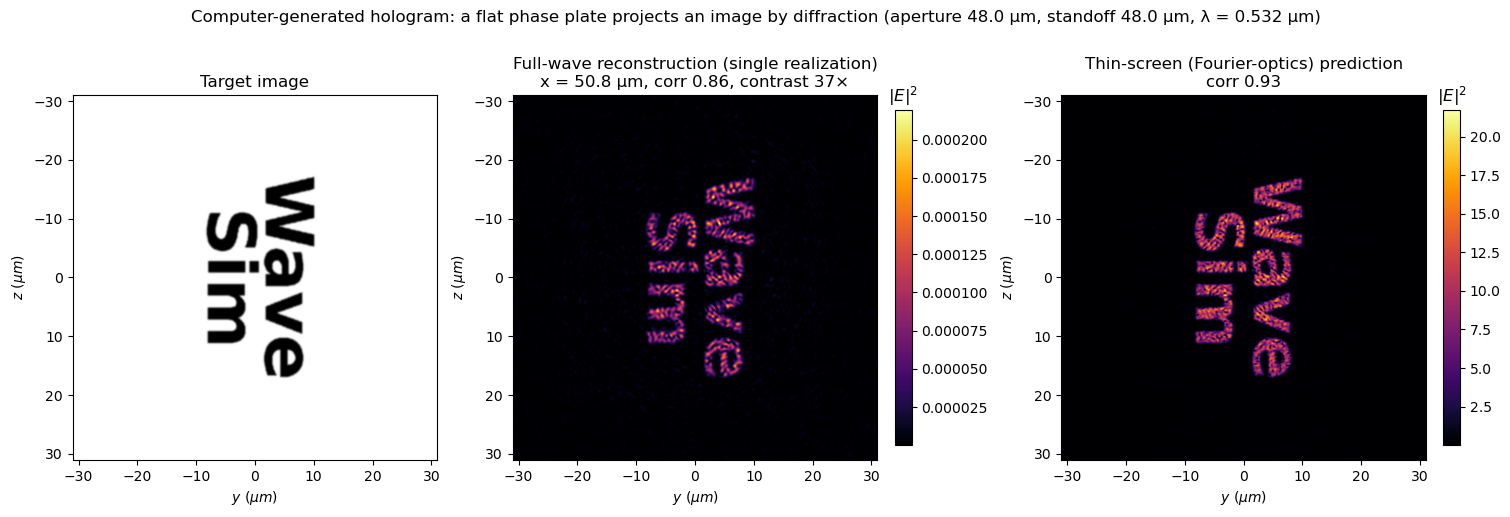

In [10]:
extent_t = [-transverse / 2, transverse / 2, transverse / 2, -transverse / 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), constrained_layout=True)

axes[0].imshow(target.T, cmap="gray_r", extent=extent_t, aspect="equal")
axes[0].set_title("Target image")

im1 = axes[1].imshow(rec_full.T, cmap="inferno", extent=extent_t, aspect="equal")
axes[1].set_title(f"Full-wave reconstruction ({avg_label})\n"
                  f"x = {x_image_meas:.1f} μm, corr {corr_full:.2f}, "
                  f"contrast {contrast_full:.0f}×")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04).ax.set_title(r"$|E|^2$")

im2 = axes[2].imshow(rec_thin.T, cmap="inferno", extent=extent_t, aspect="equal")
axes[2].set_title(f"Thin-screen (Fourier-optics) prediction\ncorr {corr_thin:.2f}")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04).ax.set_title(r"$|E|^2$")

for ax in axes:
    ax.set_xlabel(r"$y~(\mu m)$")
    ax.set_ylabel(r"$z~(\mu m)$")
fig.suptitle(f"Computer-generated hologram: a flat phase plate projects an image by "
             f"diffraction (aperture {aperture} μm, standoff {z_rec} μm, λ = {wavelength} μm)",
             fontsize=12)
fig.savefig(f"{OUTPUT_DIR}/cgh_reconstruction.png", dpi=300, bbox_inches="tight")

### Figure 2: X–Y propagation cut + near-field just past the DOE

Saved output/hmhz_hologram_cgh/cgh_reconstruction.png and output/hmhz_hologram_cgh/cgh_propagation.png


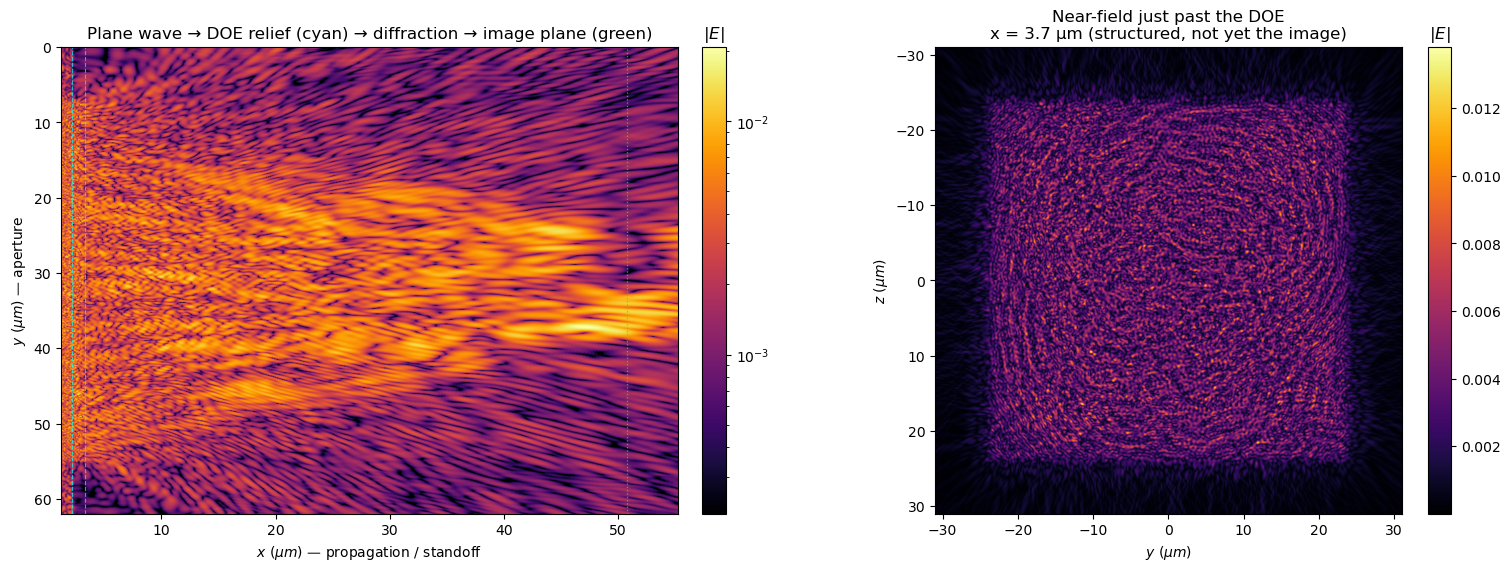

In [11]:
vmax = amp_xy.max()
vmin = vmax * 1e-2
extent_xy = [0, nx * pixel_size, ny * pixel_size, 0]  # x horizontal, y vertical (origin top)

fig2, (axp, axn) = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)

imp = axp.imshow(amp_xy.T, cmap="inferno", extent=extent_xy,
                 norm=colors.LogNorm(vmin=vmin, vmax=vmax), aspect="auto")
axp.axvline(x_relief0, color="cyan", lw=0.8, ls="--", alpha=0.7)
axp.axvline(x_relief1, color="cyan", lw=0.8, ls="--", alpha=0.7)
axp.axvline(x_image_meas, color="lime", lw=0.9, ls=":", alpha=0.8)
axp.set_xlim(x_sub0, nx * pixel_size)
axp.set_xlabel(r"$x~(\mu m)$ — propagation / standoff")
axp.set_ylabel(r"$y~(\mu m)$ — aperture")
axp.set_title("Plane wave → DOE relief (cyan) → diffraction → image plane (green)")
fig2.colorbar(imp, ax=axp, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")

imn = axn.imshow(near.T, cmap="inferno", extent=extent_t, aspect="equal")
axn.set_xlabel(r"$y~(\mu m)$")
axn.set_ylabel(r"$z~(\mu m)$")
axn.set_title(f"Near-field just past the DOE\nx = {ix_near * pixel_size:.1f} μm "
              "(structured, not yet the image)")
fig2.colorbar(imn, ax=axn, fraction=0.046, pad=0.04).ax.set_title(r"$|E|$")

fig2.savefig(f"{OUTPUT_DIR}/cgh_propagation.png", dpi=300, bbox_inches="tight")

print(f"Saved output/{NAME}/cgh_reconstruction.png and output/{NAME}/cgh_propagation.png")

plt.show()